# code_175 · Estimate an effect with independent nuisance folds

**Book:** section 33.3. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_33_GUIDE.md), [execution evidence](../CHAPTER_33_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_175).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Treatments, estimands, observed versus simulator-only outcomes, fitting roles and independent assessment are declared below. Generated interventions do not establish causal identification from arbitrary operational logs or validate an individual counterfactual.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=6475;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 6475


<a id="cross-fitted-average-effects"></a>
 ## Keep effect targets, nuisance fitting and oracle audits separate
 Generate 1,800 independent buildings with three measured covariates; outcome is annual deterioration in arbitrary teaching units. The conditional maintenance effect is−0.7−0.4 x 0. A nonlinear baseline and logistic treatment assignment create measured confounding. Compare moderate versus weak overlap using fixed assignment-strength multipliers 1 and 5. Five held-out folds fit separate treated/untreated outcome regressions and a propensity model. Compare flexible histogram boosting versus misspecified linear outcome models, and quadratic-logistic versus deliberately constant 0.5 propensities. Every nuisance prediction for a unit comes from a fold that excluded it. Oracle propensities and effects are kept only for final diagnostic truth. AIPW denominator clipping at 0.01/0.99 is disclosed; it can bias the full-population ATE score and is not called a change of target population. A normal influence-score interval is conditional on suitable nuisance/overlap assumptions, not a certified finite-sample interval.


,scenario,outcome,propensity,ATE,score_SE,normal_95,oracle_population_mean_effect,clipped_records
0,Moderate,Flexible,Quadratic logistic,-0.682274,0.016808,"[-0.7152176962728313, -0.6493304232941256]",-0.703131,0
1,Moderate,Flexible,Constant,-0.680248,0.015588,"[-0.710801527430925, -0.6496947768746681]",-0.703131,0
2,Moderate,Linear,Quadratic logistic,-0.684646,0.021723,"[-0.7272235682271196, -0.642067964296294]",-0.703131,0
3,Moderate,Linear,Constant,-0.685344,0.020382,"[-0.7252922865703584, -0.6453956644694232]",-0.703131,0
4,Weak,Flexible,Quadratic logistic,-0.736384,0.049502,"[-0.8334088902091108, -0.639359420023228]",-0.703131,233
5,Weak,Flexible,Constant,-0.643334,0.015577,"[-0.6738645880680882, -0.612803791872665]",-0.703131,0
6,Weak,Linear,Quadratic logistic,-0.673476,0.043749,"[-0.7592238501545763, -0.5877274691442003]",-0.703131,233
7,Weak,Linear,Constant,-0.653689,0.020571,"[-0.6940082908369737, -0.613369815943798]",-0.703131,0


,scenario,regression_ATE,IPW_ATE,matching_retained_ATT,oracle_retained_ATT,matched_treated,discarded_treated,unique_matched_controls,ESS_treated,ESS_control,max_abs_raw_SMD,max_abs_IPW_SMD,oracle_propensity_range
0,Moderate,-0.676826,-0.700782,-0.724997,-0.742319,985,0,475,938.936842,744.754990,0.375947,0.008204,"[0.23182545039740446, 0.8308156332898039]"
1,Weak,-0.638896,-0.589506,-0.752432,-0.798669,960,94,214,181.180205,100.212504,1.183694,0.205875,"[0.0024970095030569374, 0.9996499534508826]"


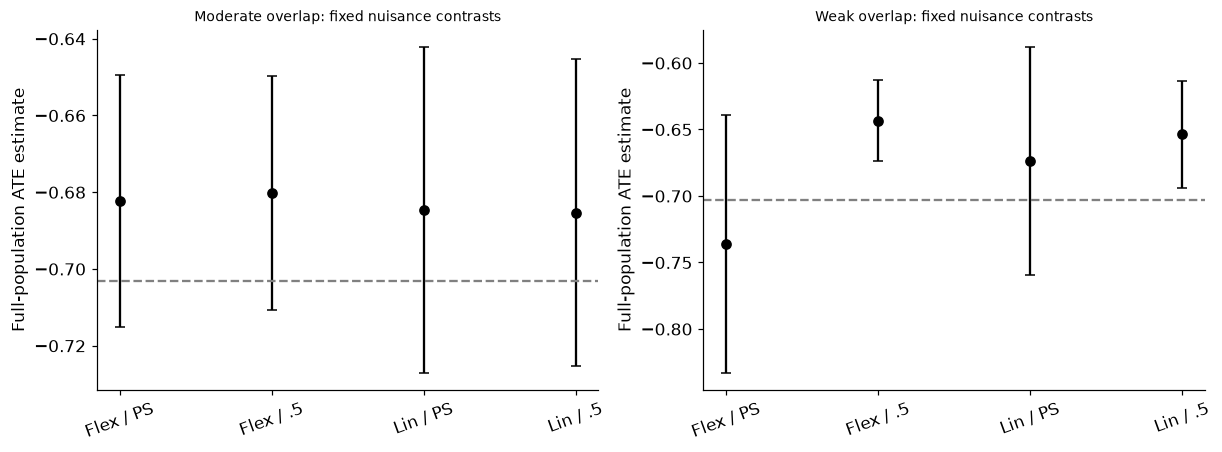

In [2]:
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor,RandomForestRegressor
def data(n,gr,strength):
    x=gr.uniform(-1,1,(n,3));tau=-.7-.4*x[:,0];m0=1+.7*x[:,0]+.8*x[:,1]**2+.4*np.sin(3*x[:,2]);logit=strength*(.8*x[:,0]-.5*x[:,1]+.5*x[:,2]**2);e=1/(1+np.exp(-logit));a=(gr.random(n)<e).astype(int);y=m0+a*tau+gr.normal(0,.3,n);return x,a,y,tau,e
cohorts={};rows=[];diagnostics=[];pseudo={};fold_ledger=[]
for scenario,strength in [('Moderate',1.),('Weak',5.)]:
    X,A,Y,tau,true_e=data(1800,np.random.default_rng(SEED),strength);cohorts[scenario]=(X,A,Y,tau,true_e);pred={name:np.zeros((1800,2)) for name in ['Flexible','Linear']};ps=np.zeros(1800)
    for fold,(fit,held) in enumerate(KFold(5,shuffle=True,random_state=SEED).split(X)):
        assert not set(fit)&set(held);fold_ledger.append({'scenario':scenario,'fold':fold,'fit':len(fit),'held':len(held)})
        propensity=make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),LogisticRegression(C=10,max_iter=500)).fit(X[fit],A[fit]);ps[held]=propensity.predict_proba(X[held])[:,1]
        for name in pred:
            for arm in [0,1]:
                ids=fit[A[fit]==arm];model=HistGradientBoostingRegressor(max_iter=80,max_leaf_nodes=7,min_samples_leaf=20,l2_regularization=1,random_state=SEED) if name=='Flexible' else LinearRegression();model.fit(X[ids],Y[ids]);pred[name][held,arm]=model.predict(X[held])
    for name in pred:
        m0,m1=pred[name].T
        for psname,rawp in [('Quadratic logistic',ps),('Constant',np.full(1800,.5))]:
            e=np.clip(rawp,.01,.99);score=m1-m0+A*(Y-m1)/e-(1-A)*(Y-m0)/(1-e);estimate=float(score.mean());se=float(score.std(ddof=1)/np.sqrt(1800));key=(scenario,name,psname);pseudo[key]=score;rows.append({'scenario':scenario,'outcome':name,'propensity':psname,'ATE':estimate,'score_SE':se,'normal_95':[estimate-1.96*se,estimate+1.96*se],'oracle_population_mean_effect':float(tau.mean()),'clipped_records':int(np.sum((rawp<.01)|(rawp>.99)))})
    e=np.clip(ps,.01,.99);w1=A/e;w0=(1-A)/(1-e);features=np.column_stack([X,X**2]);scale=np.std(features,axis=0,ddof=1);rawdiff=features[A==1].mean(0)-features[A==0].mean(0);weighted=np.average(features,weights=w1,axis=0)-np.average(features,weights=w0,axis=0)
    regression=float((pred['Flexible'][:,1]-pred['Flexible'][:,0]).mean());ipw=float(np.mean(w1*Y-w0*Y));treated=np.flatnonzero(A);controls=np.flatnonzero(1-A);logps=np.log(np.clip(ps,1e-6,1-1e-6)/(1-np.clip(ps,1e-6,1-1e-6)));dist=abs(logps[treated,None]-logps[controls][None,:]);matched=controls[dist.argmin(1)];keep=dist.min(1)<=.2*logps.std(ddof=1);kept=treated[keep];match=matched[keep]
    assert keep.any() and np.all(A[match]==0) and np.all(A[kept]==1)
    diagnostics.append({'scenario':scenario,'regression_ATE':regression,'IPW_ATE':ipw,'matching_retained_ATT':float(np.mean(Y[kept]-Y[match])),'oracle_retained_ATT':float(tau[kept].mean()),'matched_treated':len(kept),'discarded_treated':int((~keep).sum()),'unique_matched_controls':len(np.unique(match)),'ESS_treated':float(w1.sum()**2/np.sum(w1**2)),'ESS_control':float(w0.sum()**2/np.sum(w0**2)),'max_abs_raw_SMD':float(abs(rawdiff/scale).max()),'max_abs_IPW_SMD':float(abs(weighted/scale).max()),'oracle_propensity_range':[float(true_e.min()),float(true_e.max())]})
RESULTS.update(source_buildings_per_scenario=1800,nuisance_folds=5,fold_ledger=fold_ledger,AIPW=rows,diagnostics=diagnostics,denominator_clip=[.01,.99],matching_caliper_logit_SD=.2,matching_target='ATT among retained treated buildings; replacement allowed',final_outcomes_used_for_nuisance_fitting=0);display(pd.DataFrame(rows));display(pd.DataFrame(diagnostics));fig,axes=plt.subplots(1,2,figsize=(11,4))
for j,scenario in enumerate(['Moderate','Weak']):
    rr=[r for r in rows if r['scenario']==scenario];xx=np.arange(4);est=np.array([r['ATE'] for r in rr]);se=np.array([r['score_SE'] for r in rr]);axes[j].errorbar(xx,est,yerr=1.96*se,fmt='o',color='black',capsize=3);axes[j].axhline(rr[0]['oracle_population_mean_effect'],color='.5',linestyle='--');axes[j].set(xticks=xx,xticklabels=['Flex / PS','Flex / .5','Lin / PS','Lin / .5'],ylabel='Full-population ATE estimate',title=scenario+' overlap: fixed nuisance contrasts');axes[j].tick_params(axis='x',rotation=20)
plt.show()


<a id="held-out-effect-heterogeneity"></a>
 ## Use an independent target cohort and refuse tiny subgroup claims
 An original 100-tree regressor learns the flexible/quadratic-logistic cross-fitted AIPW pseudo-outcomes, minimum leaf 60. This is not an honest causal forest or an individual-effect estimator. A separate 900-building cohort supplies covariates and simulator-only conditional-effect truth for assessment; its outcomes do not fit anything. Low-load and high-load groups are fixed before assessment. A deliberately narrow high-load/high-third-covariate/low-second-covariate tail is also declared. A subgroup needs at least 40 source buildings in each treatment arm before an effect summary is reported. No threshold is tuned from final errors. Source counts, final group sizes and a refusal flag remain visible; unsupported rows use null rather than an invented precise estimate.


,scenario,region,source_controls_treated,final_buildings,reportable,mean_estimated_effect,oracle_mean_effect,conditional_effect_MAE
0,Moderate,Low load,"[478, 420]",457,True,-0.439696,-0.485454,0.075027
1,Moderate,High load,"[337, 565]",443,True,-0.900434,-0.912453,0.056348
2,Moderate,Sparse joint tail,"[0, 1]",1,False,NaN,-1.037151,NaN
3,Weak,Low load,"[602, 296]",457,True,-0.545281,-0.485454,0.167936
4,Weak,High load,"[144, 758]",443,True,-0.941887,-0.912453,0.116183
5,Weak,Sparse joint tail,"[0, 1]",1,False,NaN,-1.037151,NaN


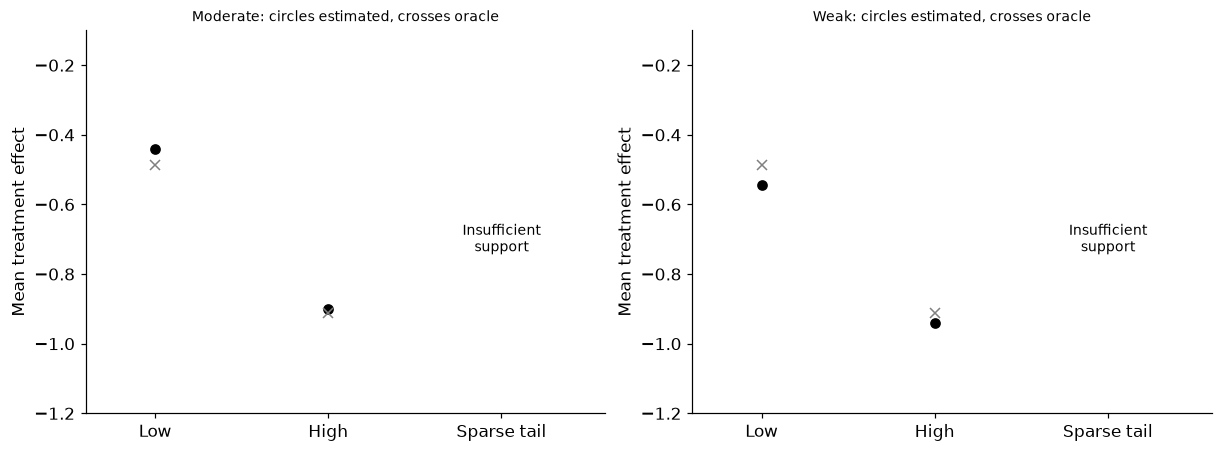

In [3]:
final_X,_,_,final_tau,_=data(900,np.random.default_rng(SEED+100),1.);heterogeneity=[]
region_functions={'Low load':lambda x:x[:,0]<0,'High load':lambda x:x[:,0]>=0,'Sparse joint tail':lambda x:(x[:,0]>.8)&(x[:,2]>.8)&(x[:,1]<-.5)}
for scenario in ['Moderate','Weak']:
    X,A,Y,tau,true_e=cohorts[scenario];model=RandomForestRegressor(n_estimators=100,min_samples_leaf=60,random_state=SEED,n_jobs=1).fit(X,pseudo[(scenario,'Flexible','Quadratic logistic')]);prediction=model.predict(final_X)
    for name,region in region_functions.items():
        mask=region(X);final_mask=region(final_X);counts=[int(np.sum(mask&(A==arm))) for arm in [0,1]];supported=min(counts)>=40 and int(final_mask.sum())>=20
        heterogeneity.append({'scenario':scenario,'region':name,'source_controls_treated':counts,'final_buildings':int(final_mask.sum()),'reportable':supported,'mean_estimated_effect':float(prediction[final_mask].mean()) if supported else None,'oracle_mean_effect':float(final_tau[final_mask].mean()) if final_mask.any() else None,'conditional_effect_MAE':float(abs(prediction[final_mask]-final_tau[final_mask]).mean()) if supported else None})
assert len(heterogeneity)==6 and any(not r['reportable'] for r in heterogeneity) and all(r['mean_estimated_effect'] is None for r in heterogeneity if not r['reportable'])
RESULTS.update(final_buildings=900,effect_learner='original RF on cross-fitted AIPW pseudo-outcomes; not honest causal forest',effect_learner_trees=100,effect_learner_min_leaf=60,minimum_source_per_arm=40,minimum_final_group=20,heterogeneity=heterogeneity);display(pd.DataFrame(heterogeneity));fig,axes=plt.subplots(1,2,figsize=(11,4))
for j,scenario in enumerate(['Moderate','Weak']):
    rr=[r for r in heterogeneity if r['scenario']==scenario]
    for k,r in enumerate(rr):
        if r['reportable']:axes[j].plot(k,r['mean_estimated_effect'],'o',color='black');axes[j].plot(k,r['oracle_mean_effect'],'x',color='.5')
        else:axes[j].text(k,-.7,'Insufficient\nsupport',ha='center',va='center',fontsize=9)
    axes[j].set(xticks=range(3),xticklabels=['Low','High','Sparse tail'],ylim=(-1.2,-.1),xlim=(-.4,2.6),ylabel='Mean treatment effect',title=scenario+': circles estimated, crosses oracle')
plt.show()


In [4]:
summary={'example_id':'code_175','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual regression adjustment propensity matching IPW and cross-fitted AIPW', 'five held-out nuisance folds with explicit misspecification contrasts', 'overlap clipping balance arm-specific effective sample sizes and matching retention', 'distinct ATE and retained-treated ATT targets', 'original pseudo-outcome effect learner with independent assessment and minimum support'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual regression adjustment propensity matching IPW and cross-fitted AIPW", "five held-out nuisance folds with explicit misspecification contrasts", "overlap clipping balance arm-specific effective sample sizes and matching retention", "distinct ATE and retained-treated ATT targets", "original pseudo-outcome effect learner with independent assessment and minimum support"], "elapsed_seconds": 1.032, "example_id": "code_175", "hardware": "Darwin arm64 CPU", "results": {"AIPW": [{"ATE": -0.6822740597834784, "clipped_records": 0, "normal_95": [-0.7152176962728313, -0.6493304232941256], "oracle_population_mean_effect": -0.7031309713740638, "outcome": "Flexible", "propensity": "Quadratic logistic", "scenario": "Moderate", "score_SE": 0.016807977800690228}, {"ATE": -0.6802481521527965, "clipped_records": 0, "normal_95": [-0.710801527430925, -0.6496947768746681], "oracle_population_mean_effect": -0.7031309713740638, "outcome": "Flexible", "pr